# Phase 3: Exploratory Data Analysis (EDA)

In this phase we analyze the dataset before modeling.

We will look at:
- distributions of numerical features
- fraud vs non-fraud behavior
- category imbalance
- suspicious patterns that may help distinguish fraud

This EDA is important because it helps us understand:
- what features matter
- whether the dataset is realistic
- which variables deserve feature engineering later

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# 1. Load the dataset

fraud_df=pd.read_csv("../data/processed/final_mini_transaction.csv") 

fraud_df.info
print()
fraud_df.dtypes

user_id            object
signup_time        object
purchase_time      object
purchase_value    float64
device_id          object
source             object
browser            object
sex                object
age                 int64
class               int64
dtype: object

In [8]:
# 2) Convert timestamps
# -----------------------------
fraud_df["signup_time"] = pd.to_datetime(fraud_df["signup_time"])
fraud_df["purchase_time"] = pd.to_datetime(fraud_df["purchase_time"])

# Check dtypes
print(fraud_df.dtypes)

user_id                   object
signup_time       datetime64[ns]
purchase_time     datetime64[ns]
purchase_value           float64
device_id                 object
source                    object
browser                   object
sex                       object
age                        int64
class                      int64
dtype: object


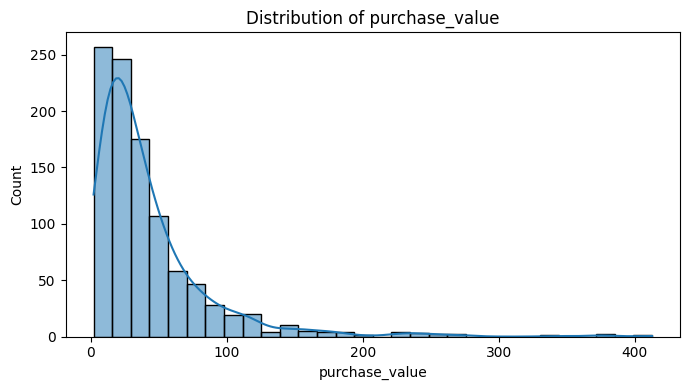

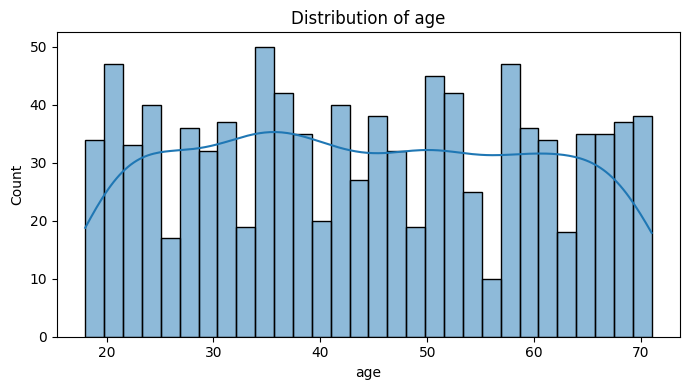

In [9]:
# -----------------------------
# 3) Univariate analysis: numerical variables
# -----------------------------
numeric_cols = ["purchase_value", "age"]

for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(fraud_df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

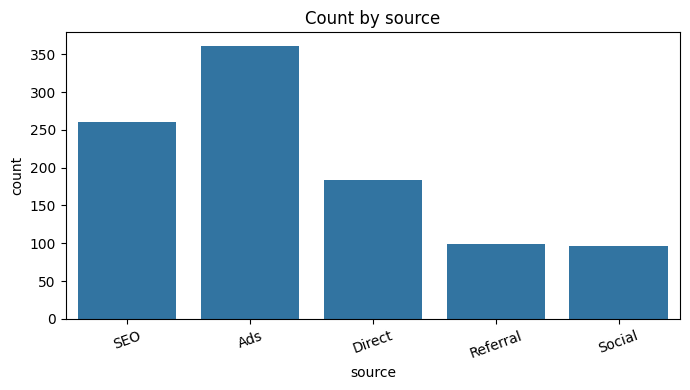

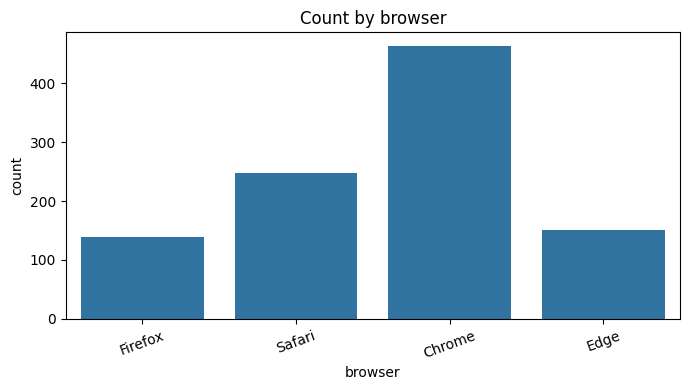

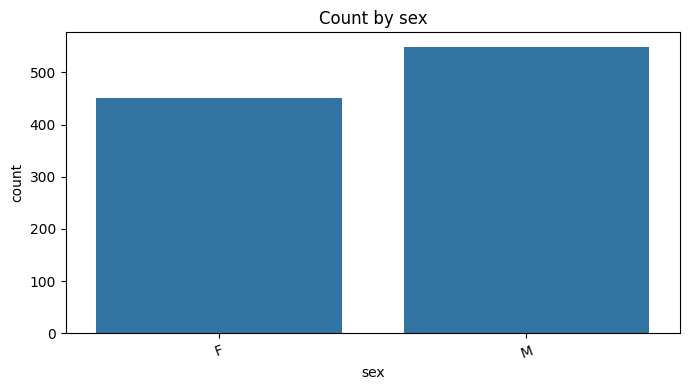

In [10]:
# -----------------------------
# 4) Univariate analysis: categorical variables
# -----------------------------
categorical_cols = ["source", "browser", "sex"]

for col in categorical_cols:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=fraud_df, x=col)
    plt.title(f"Count by {col}")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

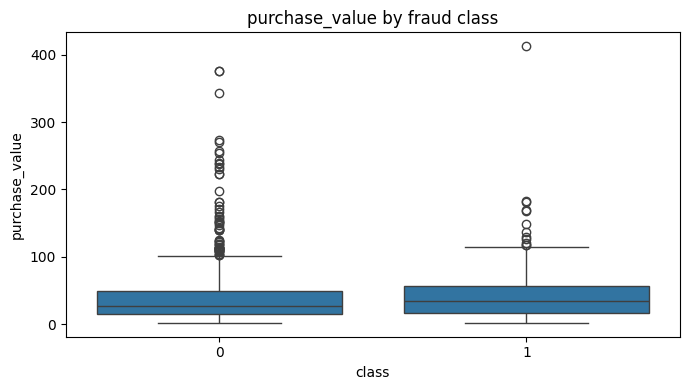

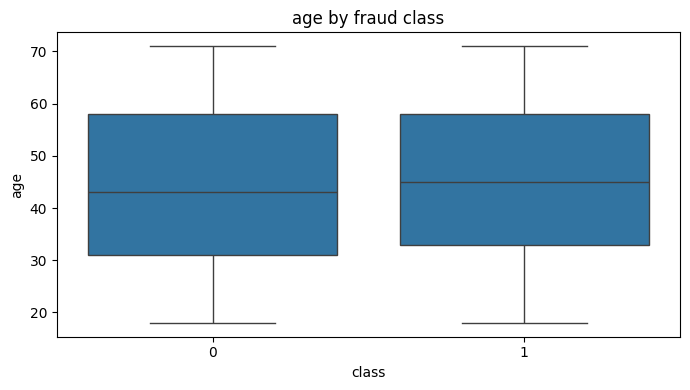

In [11]:
# -----------------------------
# 5) Compare fraudulent vs non-fraudulent transactions
# -----------------------------
# Numerical comparison
for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=fraud_df, x="class", y=col)
    plt.title(f"{col} by fraud class")
    plt.xlabel("class")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


Fraud rate by source:
source
Ads         0.207756
Direct      0.206522
Referral    0.202020
SEO         0.188462
Social      0.177083
Name: class, dtype: float64


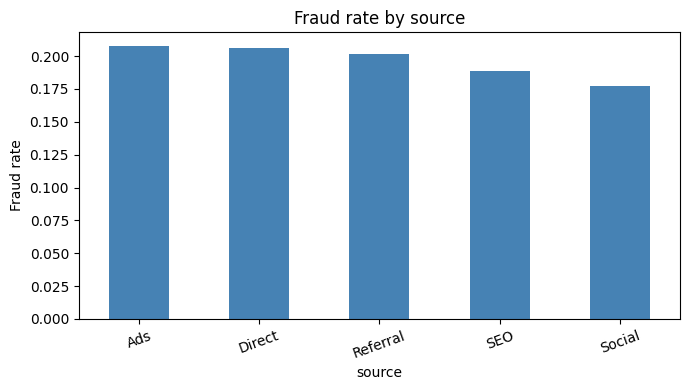


Fraud rate by browser:
browser
Safari     0.218623
Chrome     0.196544
Firefox    0.187050
Edge       0.185430
Name: class, dtype: float64


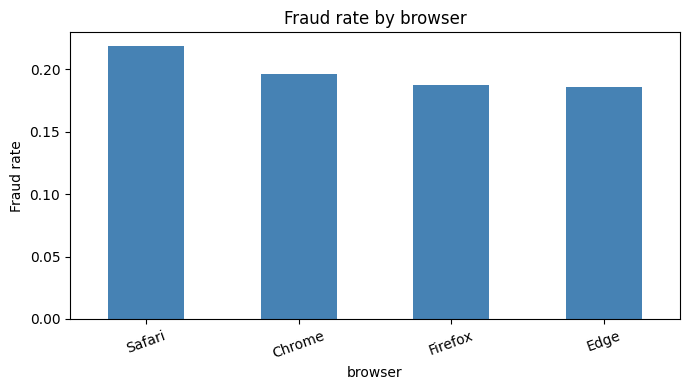


Fraud rate by sex:
sex
F    0.203991
M    0.194900
Name: class, dtype: float64


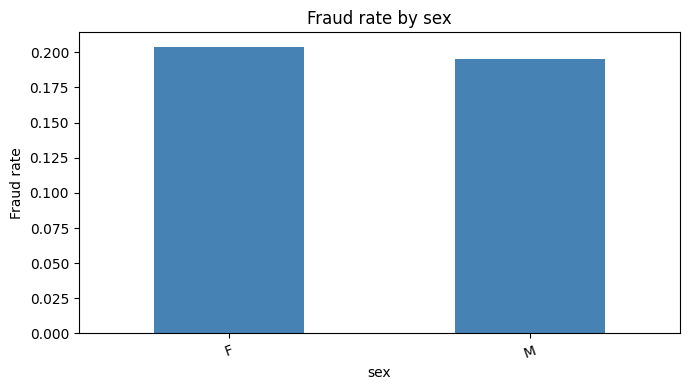

In [12]:
# -----------------------------
# 6) Bivariate analysis: fraud rate by category
# -----------------------------
for col in categorical_cols:
    fraud_rate = fraud_df.groupby(col)["class"].mean().sort_values(ascending=False)
    print(f"\nFraud rate by {col}:")
    print(fraud_rate)

    plt.figure(figsize=(7, 4))
    fraud_rate.plot(kind="bar", color="steelblue")
    plt.title(f"Fraud rate by {col}")
    plt.ylabel("Fraud rate")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_8021/3751345468.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fraud_by_value_bin = fraud_df.groupby("purchase_value_bin")["class"].mean()


purchase_value_bin
0-50         0.185637
50-100       0.232432
100-200      0.290323
200-500      0.066667
500-1000          NaN
1000-2000         NaN
2000+             NaN
Name: class, dtype: float64


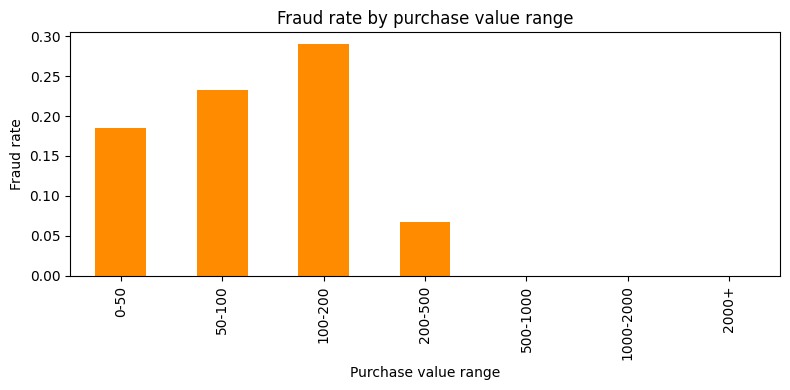

In [13]:
# -----------------------------
# 7) Fraud rate by purchase_value ranges
# -----------------------------
fraud_df["purchase_value_bin"] = pd.cut(
    fraud_df["purchase_value"],
    bins=[0, 50, 100, 200, 500, 1000, 2000, float("inf")],
    labels=["0-50", "50-100", "100-200", "200-500", "500-1000", "1000-2000", "2000+"]
)

fraud_by_value_bin = fraud_df.groupby("purchase_value_bin")["class"].mean()
print(fraud_by_value_bin)

plt.figure(figsize=(8, 4))
fraud_by_value_bin.plot(kind="bar", color="darkorange")
plt.title("Fraud rate by purchase value range")
plt.ylabel("Fraud rate")
plt.xlabel("Purchase value range")
plt.tight_layout()
plt.show()

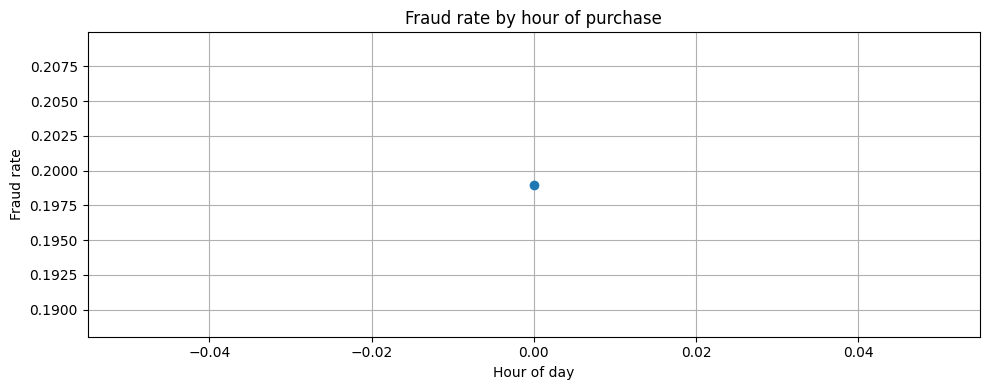

In [14]:
# -----------------------------
# 8) Time-based analysis
# -----------------------------
# Check order of transactions by time
fraud_df = fraud_df.sort_values("purchase_time").reset_index(drop=True)

# Create hour of purchase
fraud_df["purchase_hour"] = fraud_df["purchase_time"].dt.hour

# Fraud rate by hour
hour_fraud = fraud_df.groupby("purchase_hour")["class"].mean()

plt.figure(figsize=(10, 4))
hour_fraud.plot(kind="line", marker="o")
plt.title("Fraud rate by hour of purchase")
plt.xlabel("Hour of day")
plt.ylabel("Fraud rate")
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
# -----------------------------
# 9) Summary of suspicious patterns
# -----------------------------
print("Fraud rate overall:")
print(fraud_df["class"].mean())

print("\nAverage purchase_value for fraud vs non-fraud:")
print(fraud_df.groupby("class")["purchase_value"].mean())

print("\nAverage age for fraud vs non-fraud:")
print(fraud_df.groupby("class")["age"].mean())

print("\nFraud rate by source:")
print(fraud_df.groupby("source")["class"].mean())

print("\nFraud rate by browser:")
print(fraud_df.groupby("browser")["class"].mean())

Fraud rate overall:
0.199

Average purchase_value for fraud vs non-fraud:
class
0    41.143583
1    45.254070
Name: purchase_value, dtype: float64

Average age for fraud vs non-fraud:
class
0    43.971286
1    44.949749
Name: age, dtype: float64

Fraud rate by source:
source
Ads         0.207756
Direct      0.206522
Referral    0.202020
SEO         0.188462
Social      0.177083
Name: class, dtype: float64

Fraud rate by browser:
browser
Chrome     0.196544
Edge       0.185430
Firefox    0.187050
Safari     0.218623
Name: class, dtype: float64


# Findings

What the EDA tells us:

- Overall fraud rate is about 0.199, which is around 19.9%
- Fraudulent purchases have slightly higher purchase_value
    - fraud: 45.25
    - non-fraud: 41.14
- age difference is tiny
    - fraud: 44.95
    - non-fraud: 43.97
- source and browser differences are modest
    - top fraud rate by source: Ads and Direct
    - top fraud rate by browser: Safari

This means the raw features are not strongly separating fraud from legit transactions

This is important. Why? We should not rely only on the raw columns
We should engineer time-based and interaction features that capture suspicious patterns
For example:
```
purchase_hour
is_weekend
days_since_signup
purchase_value_log
is_high_value
source_ads
browser_safari
night_purchase
high_value_ads
```
This is the right transition into Phase 4.
